In [35]:
import datetime
import math
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import display


# Define the constants of the task
N = 10000000 #The notional
REPORTING_DATE = datetime.datetime(2022,9,30)
MATURITY_DATE = datetime.datetime(2024,9,30)
FIXED_INTEREST = 0.03 #The fixed interest that the bank pays per annum

ACCRUAL_START = [datetime.datetime(2022,9,30),datetime.datetime(2023,3,30),datetime.datetime(2023,9,30),datetime.datetime(2024,3,30)]
ACCRUAL_END = [datetime.datetime(2023,3,30),datetime.datetime(2023,9,30),datetime.datetime(2024,3,30),datetime.datetime(2024,9,30)]

MARKET_CURVE = {0:0.02, 0.25:0.022, 0.75:0.026, 1.25:0.029, 1.75:0.031, 2.25:0.032}

#Compute the lenghts of the legs ACT/360, ie. number of days from accrual start to end divided by 360
LEG_LENGTHS = [(ACCRUAL_END[i]-ACCRUAL_START[i]).days/360 for i in range(len(ACCRUAL_START))]

#Compute the time from reporting date in years. Compute it as number of days divided by 365.
TIME = [(ACCRUAL_END[i]-REPORTING_DATE).days/365 for i in range(len(ACCRUAL_END))]

Define some functions to help with the computations.

In [36]:
def interpolate(x,curve):
    #Interpolate values to the x coordinates, by linear interpolation of the curve.
    x_curve = list(curve.keys())
    left = 0
    values = {}
    for i in x:
        while left<len(x_curve):
            if i>x_curve[left] and i<=x_curve[left+1]:
                values[i] = curve[x_curve[left]]+(i-x_curve[left])*(curve[x_curve[left+1]]-curve[x_curve[left]])/(x_curve[left+1]-x_curve[left])
                break
            else:
                left+=1
    return values


def discount_factors(curve):
    #Calculate the discount factors from the curve. We assume continuous compound of interest, so discount is D(T)=e^(-z(T)T)
    discount = {}
    for i in curve:
        discount[i] = math.exp(-curve[i]*i)
    return discount

def floating_receipt_rates(discount):
    #Return the floating receipt rates F_i. F_0 is fixed to 2,5%. for i>0, F_i=(D(T_(i-1))/D(T_i)-1)/t_i, where D is the discount factor and t_i is the ACT/360 accrual fraction.
    F = [0.025]
    discounts = list(discount.values())
    for i in range(1,4):
        F.append((discounts[i-1]/discounts[i]-1)/LEG_LENGTHS[i])
    return F

def floating_receipts(F):
    #Return the value of the floating receipts
    return [N*F[i]*LEG_LENGTHS[i] for i in range(4)]

A.
To calculate present values, I create a dataframe that holds all of the relevant information.

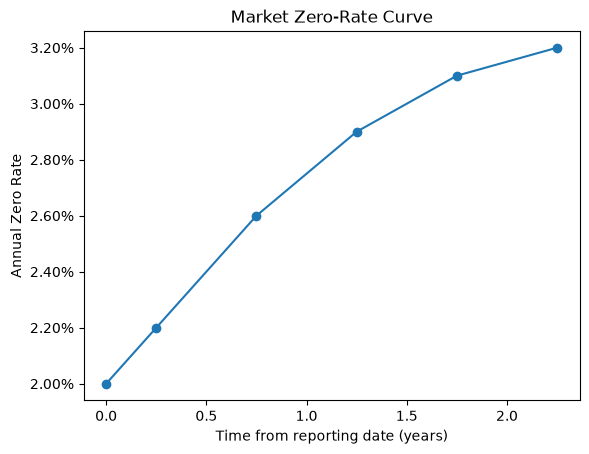

In [37]:
#Plot the market curve
plt.plot(MARKET_CURVE.keys(),MARKET_CURVE.values(),marker = "o")
plt.title("Market Zero-Rate Curve")
plt.xlabel("Time from reporting date (years)")
plt.ylabel("Annual Zero Rate")
plt.gca().yaxis.set_major_formatter(PercentFormatter(xmax=1))
plt.show()

In [38]:
#Interpolate the values
interpolated_values = interpolate(TIME,MARKET_CURVE)
#Compute discount factors
discount_factors_regular = discount_factors(interpolated_values)
#Compute F_i
F = floating_receipt_rates(discount_factors_regular)
floating_r = floating_receipts(F)

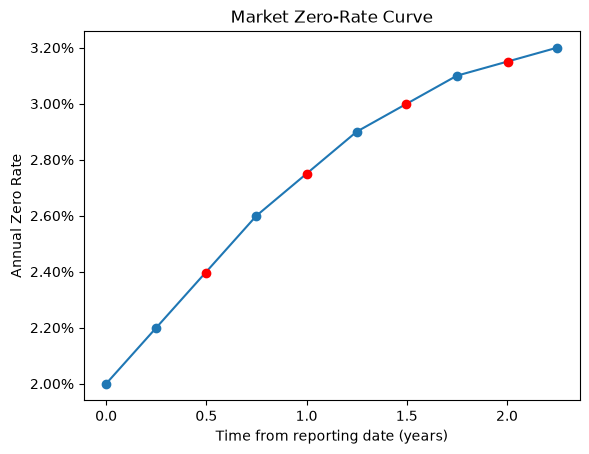

In [39]:
#Plot the market curve with the interpolated points
plt.plot(MARKET_CURVE.keys(),MARKET_CURVE.values(),marker = "o")
plt.title("Market Zero-Rate Curve")
plt.xlabel("Time from reporting date (years)")
plt.ylabel("Annual Zero Rate")
plt.gca().yaxis.set_major_formatter(PercentFormatter(xmax=1))
plt.scatter(
    interpolated_values.keys(),
    interpolated_values.values(),
    color="red",
    marker="o",
    zorder=3,
    label="Interpolated points"
)
plt.show()

In [51]:
#Create a dataframe that has fixed coupon and floating coupon and their present values
df = pd.DataFrame({"Time from reporting date":TIME, "Length of leg":LEG_LENGTHS, "Interpolated curve rate":interpolated_values.values(), "D(T)": discount_factors_regular.values(), "F_i": F},index = ACCRUAL_END)
df["Floating Receipt"] = N*df["Length of leg"]*df["F_i"]
df["PV Floating Receipt"] = df["Floating Receipt"]*df["D(T)"]
df["Fixed Coupon"] = df["Length of leg"]*N*FIXED_INTEREST
df["PV Fixed Coupon"] = df["Fixed Coupon"]*df["D(T)"]

display(df)

,Time from reporting date,Length of leg,Interpolated curve rate,D(T),F_i,Floating Receipt,PV Floating Receipt,Fixed Coupon,PV Fixed Coupon
2023-03-30,0.49589,0.502778,0.023967,0.988185,0.025000,125694.444444,124209.400006,150833.333333,149051.280007
2023-09-30,1.00000,0.511111,0.027500,0.972875,0.030791,157374.834954,153105.992598,153333.333333,149174.117992
2024-03-30,1.49863,0.505556,0.029995,0.956045,0.034821,176038.453486,168300.616527,151666.666667,145000.100837
2024-09-30,2.00274,0.511111,0.031505,0.938852,0.035828,183122.325581,171924.787645,153333.333333,143957.328461


In [52]:
#Compute the value of the swap
PV_float = df["PV Floating Receipt"].sum()
PV_fixed = df["PV Fixed Coupon"].sum()
V = PV_float-PV_fixed
print(f"Total floating-leg PV: {PV_float:.2f}€")
print(f"Total fixed-leg PV: {PV_fixed:.2f}€")
print(f"Value of swap: {V:.2f}€")

Total floating-leg PV: 617540.80€
Total fixed-leg PV: 587182.83€
Value of swap: 30357.97€


B.
First we compute the shifted market-curve and then interpolate the new values. Calculate the value of the swap again.

In [ ]:
#Shift the market curve by 1 bp
shifted_curve = {i:MARKET_CURVE[i]+0.0001 for i in MARKET_CURVE}
interpolated_values_shifted = interpolate(TIME,shifted_curve)


In [54]:
#Compute the D(T) and floating coupons for shifted curve
discount_factors_shifted = discount_factors(interpolated_values_shifted)
F_shifted = floating_receipt_rates(discount_factors_shifted)
df["Shifted Zero Rate"] = interpolated_values_shifted.values()
df["Shifted Discount factor"] = discount_factors_shifted.values()
df["F_i shifted"] = F_shifted
df["Floating Coupons Shifted"] = N*df["F_i shifted"]*df["Length of leg"]

#Compute PV for shifed coupons 
df["PV Floating Shifted"] = df["Floating Coupons Shifted"]*df["Shifted Discount factor"]
df["PV Fixed Shifted"] = df["Fixed Coupon"]*df["Shifted Discount factor"]

display(df)

,Time from reporting date,Length of leg,Interpolated curve rate,D(T),F_i,Floating Receipt,PV Floating Receipt,Fixed Coupon,PV Fixed Coupon,Shifted Zero Rate,Shifted Discount factor,F_i shifted,Floating Coupons Shifted,PV Floating Shifted,PV Fixed Shifted
2023-03-30,0.49589,0.502778,0.023967,0.988185,0.025000,125694.444444,124209.400006,150833.333333,149051.280007,0.024067,0.988136,0.025000,125694.444444,124203.240733,149043.888880
2023-09-30,1.00000,0.511111,0.027500,0.972875,0.030791,157374.834954,153105.992598,153333.333333,149174.117992,0.027600,0.972777,0.030891,157886.890866,153588.799182,149159.201326
2024-03-30,1.49863,0.505556,0.029995,0.956045,0.034821,176038.453486,168300.616527,151666.666667,145000.100837,0.030095,0.955901,0.034921,176545.874082,168760.440415,144978.372313
2024-09-30,2.00274,0.511111,0.031505,0.938852,0.035828,183122.325581,171924.787645,153333.333333,143957.328461,0.031605,0.938664,0.035929,183635.679481,172372.225926,143928.500442


In [55]:
#The value V for the shifted curve
PV_floating_shifted = df["PV Floating Shifted"].sum()
PV_fixed_shifted = df["PV Fixed Shifted"].sum()
V_shifted = PV_floating_shifted-PV_fixed_shifted
#The difference to the original value
PV01 = V_shifted-V
#The change is positive
#Interest rate delta
delta = PV01*100
print()
print(f"PV01: +{PV01:.2f}€")
print(f"Interest rate delta: {delta:.2f}€")


PV01: +1456.77€
Interest rate delta: 145677.38€


C:
Finally apply 20% relative stress to the market curve and apply the new discount to the original base coupons.

In [56]:
#apply 20% relative increase to the market curve
stressed_curve = {i:MARKET_CURVE[i]*1.2 for i in MARKET_CURVE}
interpolated_values_stressed = interpolate(TIME,stressed_curve)

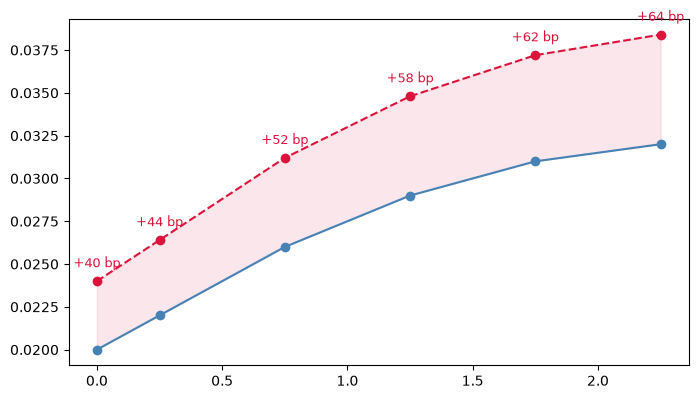

In [61]:
fig, ax = plt.subplots(figsize=(8, 4.5))

x = MARKET_CURVE.keys()
y = MARKET_CURVE.values()
y_stressed = stressed_curve.values()

ax.plot(x, y, "o-", color="steelblue", label="Base curve")
ax.plot(
    x, y_stressed, "o--",
    color="crimson",
    label="Stressed curve (+20% relative)"
)

ax.fill_between(x, y, y_stressed, color="crimson", alpha=0.10)

# Label the increase at each node in basis points
for t, base, stressed in zip(x, y, y_stressed):
    ax.annotate(
        f"+{(stressed - base) * 10000:.0f} bp",
        xy=(t, stressed),
        xytext=(0, 10),
        textcoords="offset points",
        ha="center",
        fontsize=9,
        color="crimson"
    )

In [57]:
#Compute the new discount factors
df["Stressed Discount"] = discount_factors(interpolated_values_stressed).values()
#Compute Stressed PV for each leg, stressed market value and P&L relative to base valuation
df["PV Floating Stressed (€)"] = df["Floating Receipt"]*df["Stressed Discount"]
df["PV Fixed Stressed (€)"] = df["Fixed Coupon"]*df["Stressed Discount"]

display(df)

,Time from reporting date,Length of leg,Interpolated curve rate,D(T),F_i,Floating Receipt,PV Floating Receipt,Fixed Coupon,PV Fixed Coupon,Shifted Zero Rate,Shifted Discount factor,F_i shifted,Floating Coupons Shifted,PV Floating Shifted,PV Fixed Shifted,Stressed Discount,PV Floating Stressed (€),PV Fixed Stressed (€)
2023-03-30,0.49589,0.502778,0.023967,0.988185,0.025000,125694.444444,124209.400006,150833.333333,149051.280007,0.024067,0.988136,0.025000,125694.444444,124203.240733,149043.888880,0.985839,123914.503233,148697.403879
2023-09-30,1.00000,0.511111,0.027500,0.972875,0.030791,157374.834954,153105.992598,153333.333333,149174.117992,0.027600,0.972777,0.030891,157886.890866,153588.799182,149159.201326,0.967539,152266.221127,148355.912470
2024-03-30,1.49863,0.505556,0.029995,0.956045,0.034821,176038.453486,168300.616527,151666.666667,145000.100837,0.030095,0.955901,0.034921,176545.874082,168760.440415,144978.372313,0.947488,166794.351587,143702.371971
2024-09-30,2.00274,0.511111,0.031505,0.938852,0.035828,183122.325581,171924.787645,153333.333333,143957.328461,0.031605,0.938664,0.035929,183635.679481,172372.225926,143928.500442,0.927079,169768.822677,142152.080007


In [59]:
# Stressed market value
PV_fixed_stressed = df["PV Fixed Stressed (€)"].sum()
PV_floating_stressed = df["PV Floating Stressed (€)"].sum()
V_stressed = PV_floating_stressed-PV_fixed_stressed
# relative P&L to base valuation
PL = V_stressed - V
print(f"PV of stressed floating leg: {PV_floating_stressed:.2f} €")
print(f"PV of stressed fixed leg: {PV_fixed_stressed:.2f} €")
print(f"Stressed market value: {V_stressed:.2f} €")
print(f"Stress P&L relative to base valuation: {PL:.2f} €")
#display(df[["PV Fixed Stressed (€)","PV Floating Stressed (€)"]].style.format({"PV Fixed Stressed (€)":"{:,.2f}", "PV Floating Stressed (€)":"{:,.2f}"}).format_index(lambda date: date.strftime("%d.%m.%Y"), axis=0))

PV of stressed floating leg: 612743.90 €
PV of stressed fixed leg: 582907.77 €
Stressed market value: 29836.13 €
Stress P&L relative to base valuation: -521.84 €
